# Vocabulary Network: Folio Communities from Shared Content Words

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from collections import defaultdict, Counter
from itertools import combinations
from scipy.stats import chi2_contingency

try:
    from networkx.algorithms.community import louvain_communities
    HAS_LOUVAIN = True
except ImportError:
    HAS_LOUVAIN = False
from networkx.algorithms.community import greedy_modularity_communities
from networkx.algorithms.community.quality import modularity

print('All imports OK')
print(f'NetworkX version: {nx.__version__}')
print(f'Louvain available: {HAS_LOUVAIN}')

All imports OK
NetworkX version: 3.6.1
Louvain available: True


In [2]:
# ── Cell 2: Full pipeline — STA1 parser + TP-P20 + tier classification ──
STA_PATH = 'corpus/voynich_sta.txt'

# ── Parser ──
def parse_sta_with_positions(filepath):
    records = []
    current_folio = 'unknown'
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', line)
            if not match:
                continue
            tag = match.group(1).strip()
            folio_match = re.match(r'(f\d+[rv]\d*)', tag)
            if folio_match:
                current_folio = folio_match.group(1)
            texto = match.group(2).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            pos_in_line = 0
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    records.append({
                        'folio': current_folio,
                        'line_tag': tag,
                        'pos_in_line': pos_in_line,
                        'glyphs': tuple(glifos),
                        'word_str': '.'.join(glifos),
                    })
                    pos_in_line += 1
    return records

records = parse_sta_with_positions(STA_PATH)
print(f'Total word tokens parsed: {len(records):,}')

# ── Section classification ──
SECTIONS = ['herbal', 'astro', 'zodiac', 'bio', 'pharma', 'recipe']
SECTION_COLORS = {
    'herbal': '#2ca02c',   # green
    'astro': '#1f77b4',    # blue
    'zodiac': '#9467bd',   # purple
    'bio': '#d62728',      # red
    'pharma': '#8c564b',   # brown
    'recipe': '#ff7f0e',   # orange
    'unknown': '#7f7f7f',  # grey
}

def classify_folio(tag):
    m = re.search(r'f(\d+)', tag)
    if not m:
        return 'unknown'
    n = int(m.group(1))
    if 1 <= n <= 56:
        return 'herbal'
    elif 57 <= n <= 67:
        return 'astro'
    elif 68 <= n <= 73:
        return 'zodiac'
    elif 74 <= n <= 84:
        return 'bio'
    elif 85 <= n <= 86:
        return 'pharma'
    elif n >= 87:
        return 'recipe'
    return 'unknown'

for rec in records:
    rec['section'] = classify_folio(rec['folio'])

# ── Build transition matrix for TP-P20 segmentation ──
all_words = [list(rec['glyphs']) for rec in records]
all_glyphs_flat = [g for w in all_words for g in w]
VOCAB = sorted(set(all_glyphs_flat))
n_glyphs = len(VOCAB)
glyph_index = {g: i for i, g in enumerate(VOCAB)}

M_raw = np.zeros((n_glyphs, n_glyphs))
for word in all_words:
    for i in range(len(word) - 1):
        r, c = glyph_index[word[i]], glyph_index[word[i + 1]]
        M_raw[r, c] += 1
row_sums = M_raw.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
M_prob = M_raw / row_sums

all_tp = []
for word in all_words:
    for i in range(len(word) - 1):
        p = M_prob[glyph_index[word[i]], glyph_index[word[i + 1]]]
        if p > 0:
            all_tp.append(p)
all_tp = np.array(all_tp)
threshold_val = np.percentile(all_tp, 20)
print(f'TP-P20 threshold: {threshold_val:.4f}')

# ── Segment words into syllables ──
def segment_word(word):
    if not word:
        return []
    syl = [word[0]]
    result = []
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i + 1]
        if g1 in glyph_index and g2 in glyph_index:
            p = M_prob[glyph_index[g1], glyph_index[g2]]
        else:
            p = 0.0
        if p < threshold_val:
            result.append(tuple(syl))
            syl = [g2]
        else:
            syl.append(g2)
    result.append(tuple(syl))
    return result

all_syls = [segment_word(word) for word in all_words]

# ── Classify syllables by positional preference ──
syl_pos_counts = defaultdict(lambda: Counter())
for word_syls in all_syls:
    n_syls = len(word_syls)
    if n_syls == 1:
        syl_pos_counts[word_syls[0]]['free'] += 1
    else:
        for j, syl in enumerate(word_syls):
            if j == 0:
                syl_pos_counts[syl]['onset'] += 1
            elif j == n_syls - 1:
                syl_pos_counts[syl]['coda'] += 1
            else:
                syl_pos_counts[syl]['nuclear'] += 1

MIN_FREQ = 5
clase_silaba = {}
for syl, counts in syl_pos_counts.items():
    total = sum(counts.values())
    if total < MIN_FREQ:
        clase_silaba[syl] = 'free'
        continue
    best_class = max(counts, key=counts.get)
    if counts[best_class] / total >= 0.6:
        clase_silaba[syl] = best_class
    else:
        clase_silaba[syl] = 'free'

# ── Classify each word into tier ──
CLASS_ABBREV = {'onset': 'O', 'nuclear': 'N', 'coda': 'C', 'free': 'F'}

def word_pattern(word_syls):
    classes = [clase_silaba.get(syl, 'free') for syl in word_syls]
    return '-'.join(CLASS_ABBREV[c] for c in classes)

def word_tier(word_syls):
    pattern = word_pattern(word_syls)
    return 'T1' if pattern == 'F' else 'T2'

for rec, ws in zip(records, all_syls):
    rec['syllables'] = ws
    rec['tier'] = word_tier(ws)
    rec['pattern'] = word_pattern(ws)

df = pd.DataFrame(records)
tier_counts = df['tier'].value_counts()
print(f'\nTier distribution:')
print(f'  T1 (functional): {tier_counts.get("T1", 0):,} ({tier_counts.get("T1", 0)/len(df):.1%})')
print(f'  T2 (content):    {tier_counts.get("T2", 0):,} ({tier_counts.get("T2", 0)/len(df):.1%})')
print(f'\nFolios: {df["folio"].nunique()}')
print(f'Sections: {df["section"].value_counts().to_dict()}')

Total word tokens parsed: 37,087
TP-P20 threshold: 0.0902

Tier distribution:
  T1 (functional): 17,890 (48.2%)
  T2 (content):    19,197 (51.8%)

Folios: 226
Sections: {'recipe': 14385, 'herbal': 9167, 'bio': 6768, 'zodiac': 2465, 'pharma': 2338, 'astro': 1964}


In [3]:
# ── Cell 3: Build folio x T2 word matrix ────────────────────────────
# For each folio, collect all T2 words (as tuples). Build a matrix:
# folios x T2_word_types, values = frequency.

df_t2 = df[df['tier'] == 'T2'].copy()
print(f'T2 tokens: {len(df_t2):,}')
print(f'T2 word types: {df_t2["word_str"].nunique():,}')

# Build folio -> T2 word frequency
folio_t2_freq = defaultdict(Counter)
for _, row in df_t2.iterrows():
    folio_t2_freq[row['folio']][row['word_str']] += 1

folios_list = sorted(folio_t2_freq.keys(),
                     key=lambda f: (int(re.search(r'(\d+)', f).group(1)),
                                    f.replace(re.search(r'\d+', f).group(), '')))
all_t2_types = sorted(set(w for cnt in folio_t2_freq.values() for w in cnt))
t2_idx = {w: i for i, w in enumerate(all_t2_types)}

# Build the matrix
mat = np.zeros((len(folios_list), len(all_t2_types)), dtype=np.float32)
for i, fol in enumerate(folios_list):
    for w, cnt in folio_t2_freq[fol].items():
        mat[i, t2_idx[w]] = cnt

print(f'\nFolio x T2-type matrix: {mat.shape}')
print(f'Non-zero entries: {(mat > 0).sum():,}')
print(f'Sparsity: {1 - (mat > 0).sum() / mat.size:.1%}')

# Folio metadata
folio_section = {}
folio_word_count = {}
for fol in folios_list:
    folio_section[fol] = classify_folio(fol)
    folio_word_count[fol] = len(df[df['folio'] == fol])

T2 tokens: 19,197
T2 word types: 8,567

Folio x T2-type matrix: (225, 8567)
Non-zero entries: 17,233
Sparsity: 99.1%


In [4]:
# ── Cell 4: Build co-occurrence network ─────────────────────────────
# Nodes = folios. Edge weight = Jaccard similarity of T2 vocabulary.
# Only edges where Jaccard > threshold.

JACCARD_THRESHOLD = 0.05

# Precompute binary sets for Jaccard
folio_sets = {}
for i, fol in enumerate(folios_list):
    folio_sets[fol] = set(np.where(mat[i] > 0)[0])

G = nx.Graph()
for fol in folios_list:
    G.add_node(fol, section=folio_section[fol],
               word_count=folio_word_count[fol])

n_edges_added = 0
jaccard_values = []
for i, f1 in enumerate(folios_list):
    s1 = folio_sets[f1]
    if not s1:
        continue
    for j in range(i + 1, len(folios_list)):
        f2 = folios_list[j]
        s2 = folio_sets[f2]
        if not s2:
            continue
        intersection = len(s1 & s2)
        union = len(s1 | s2)
        if union == 0:
            continue
        jacc = intersection / union
        if jacc > JACCARD_THRESHOLD:
            G.add_edge(f1, f2, weight=jacc)
            n_edges_added += 1
        jaccard_values.append(jacc)

jaccard_values = np.array(jaccard_values)

print(f'NETWORK SUMMARY')
print(f'=' * 50)
print(f'Jaccard threshold:      {JACCARD_THRESHOLD}')
print(f'Nodes (folios):         {G.number_of_nodes()}')
print(f'Edges:                  {G.number_of_edges()}')
degrees = [d for _, d in G.degree()]
print(f'Mean degree:            {np.mean(degrees):.1f}')
print(f'Median degree:          {np.median(degrees):.0f}')
print(f'Connected components:   {nx.number_connected_components(G)}')
print(f'\nJaccard distribution (all pairs):')
print(f'  Mean:   {jaccard_values.mean():.4f}')
print(f'  Median: {np.median(jaccard_values):.4f}')
print(f'  Max:    {jaccard_values.max():.4f}')
print(f'  > 0.05: {(jaccard_values > 0.05).sum()} / {len(jaccard_values)} pairs')

NETWORK SUMMARY
Jaccard threshold:      0.05
Nodes (folios):         225
Edges:                  1883
Mean degree:            16.7
Median degree:          14
Connected components:   17

Jaccard distribution (all pairs):
  Mean:   0.0236
  Median: 0.0211
  Max:    0.1282
  > 0.05: 1883 / 25200 pairs


In [5]:
# ── Cell 5: Community detection ─────────────────────────────────────
# Louvain (preferred) or greedy modularity as fallback.

if HAS_LOUVAIN:
    communities_raw = louvain_communities(G, weight='weight', seed=42)
    method_name = 'Louvain'
else:
    communities_raw = list(greedy_modularity_communities(G, weight='weight'))
    method_name = 'Greedy modularity'

# Sort communities by size (largest first)
communities = sorted(communities_raw, key=len, reverse=True)
n_communities = len(communities)

# Assign community labels to nodes
node_community = {}
for cid, members in enumerate(communities):
    for node in members:
        node_community[node] = cid

mod_score = modularity(G, communities, weight='weight')

print(f'COMMUNITY DETECTION ({method_name})')
print(f'=' * 50)
print(f'Communities found:  {n_communities}')
print(f'Modularity score:   {mod_score:.4f}')
print()

for cid, members in enumerate(communities):
    sections_in_comm = [folio_section[n] for n in members]
    sec_counts = Counter(sections_in_comm)
    dominant = sec_counts.most_common(3)
    dom_str = ', '.join(f'{s} ({c})' for s, c in dominant)
    print(f'  Community {cid}: {len(members):>3} folios | {dom_str}')

COMMUNITY DETECTION (Louvain)
Communities found:  20
Modularity score:   0.4588

  Community 0:  72 folios | herbal (71), recipe (1)
  Community 1:  60 folios | recipe (23), herbal (17), zodiac (15)
  Community 2:  52 folios | recipe (23), bio (20), pharma (6)
  Community 3:  25 folios | herbal (18), recipe (6), astro (1)
  Community 4:   1 folios | herbal (1)
  Community 5:   1 folios | herbal (1)
  Community 6:   1 folios | herbal (1)
  Community 7:   1 folios | herbal (1)
  Community 8:   1 folios | astro (1)
  Community 9:   1 folios | astro (1)
  Community 10:   1 folios | astro (1)
  Community 11:   1 folios | zodiac (1)
  Community 12:   1 folios | zodiac (1)
  Community 13:   1 folios | zodiac (1)
  Community 14:   1 folios | zodiac (1)
  Community 15:   1 folios | zodiac (1)
  Community 16:   1 folios | zodiac (1)
  Community 17:   1 folios | zodiac (1)
  Community 18:   1 folios | recipe (1)
  Community 19:   1 folios | recipe (1)


In [6]:
# ── Cell 6: Community x section cross-tabulation + chi-squared ──────

# Build cross-tab
rows = []
for fol in folios_list:
    if fol in node_community:
        rows.append({'folio': fol, 'community': node_community[fol],
                      'section': folio_section[fol]})
df_comm = pd.DataFrame(rows)

ct = pd.crosstab(df_comm['community'], df_comm['section'])
print('Community x Section cross-tabulation:')
print(ct.to_string())
print()

# Chi-squared test
chi2, p_val, dof, expected = chi2_contingency(ct.values)
print(f'Chi-squared test:')
print(f'  chi2 = {chi2:.2f},  dof = {dof},  p = {p_val:.2e}')
if p_val < 0.001:
    print(f'  => Highly significant: communities DO correspond to sections.')
elif p_val < 0.05:
    print(f'  => Significant at alpha=0.05.')
else:
    print(f'  => NOT significant: communities do not correspond to sections.')

Community x Section cross-tabulation:
section    astro  bio  herbal  pharma  recipe  zodiac
community                                            
0              0    0      71       0       1       0
1              5    0      17       0      23      15
2              3   20       0       6      23       0
3              1    0      18       0       6       0
4              0    0       1       0       0       0
5              0    0       1       0       0       0
6              0    0       1       0       0       0
7              0    0       1       0       0       0
8              1    0       0       0       0       0
9              1    0       0       0       0       0
10             1    0       0       0       0       0
11             0    0       0       0       0       1
12             0    0       0       0       0       1
13             0    0       0       0       0       1
14             0    0       0       0       0       1
15             0    0       0       0       

In [7]:
# ── Cell 7: Community x onset family cross-tabulation ────────────────
# Compute dominant onset family per folio from the data.
# An onset family = the most frequent onset syllable class in the folio's T2 words.

# For each folio, find the most frequent onset syllable (first syllable of T2 words)
folio_onset_freq = defaultdict(Counter)
for rec, ws in zip(records, all_syls):
    if rec['tier'] == 'T2' and len(ws) >= 2:
        onset_syl = ws[0]  # first syllable (onset position)
        folio_onset_freq[rec['folio']][onset_syl] += 1

# Cluster onsets into families using co-occurrence with codas
# Collect all onsets and codas from T2 words
onset_counter = Counter()
coda_counter = Counter()
onset_coda_pairs = Counter()

for rec, ws in zip(records, all_syls):
    if rec['tier'] == 'T2' and len(ws) >= 2:
        onset = ws[0]
        coda = ws[-1]
        onset_counter[onset] += 1
        coda_counter[coda] += 1
        onset_coda_pairs[(onset, coda)] += 1

# Keep only frequent onsets
MIN_ONSET_FREQ = 20
freq_onsets = sorted([o for o, c in onset_counter.items() if c >= MIN_ONSET_FREQ],
                     key=lambda x: -onset_counter[x])
freq_codas = sorted([c for c, cnt in coda_counter.items() if cnt >= MIN_ONSET_FREQ],
                    key=lambda x: -coda_counter[x])

print(f'Frequent onsets (>={MIN_ONSET_FREQ}): {len(freq_onsets)}')
print(f'Frequent codas  (>={MIN_ONSET_FREQ}): {len(freq_codas)}')

# Build onset-coda co-occurrence matrix and cluster onsets
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

if len(freq_onsets) >= 4 and len(freq_codas) >= 2:
    onset_idx = {o: i for i, o in enumerate(freq_onsets)}
    coda_idx = {c: i for i, c in enumerate(freq_codas)}
    cooc = np.zeros((len(freq_onsets), len(freq_codas)))
    for (o, c), cnt in onset_coda_pairs.items():
        if o in onset_idx and c in coda_idx:
            cooc[onset_idx[o], coda_idx[c]] = cnt
    # Normalize rows
    row_sums_oc = cooc.sum(axis=1, keepdims=True)
    row_sums_oc[row_sums_oc == 0] = 1
    cooc_norm = cooc / row_sums_oc
    
    # Cluster onsets
    dist = pdist(cooc_norm, metric='cosine')
    dist = np.nan_to_num(dist, nan=1.0)
    Z = linkage(dist, method='ward')
    
    # Find optimal k (2-8)
    from sklearn.metrics import silhouette_score
    best_k, best_sil = 2, -1
    for k in range(2, min(9, len(freq_onsets))):
        labels = fcluster(Z, t=k, criterion='maxclust')
        if len(set(labels)) < 2:
            continue
        try:
            sil = silhouette_score(cooc_norm, labels, metric='cosine')
            if sil > best_sil:
                best_sil = sil
                best_k = k
        except:
            pass
    
    onset_family_labels = fcluster(Z, t=best_k, criterion='maxclust')
    onset_to_family = {freq_onsets[i]: int(onset_family_labels[i]) for i in range(len(freq_onsets))}
    print(f'Onset families (k={best_k}, silhouette={best_sil:.3f}):')
    for fam in sorted(set(onset_family_labels)):
        members = [freq_onsets[i] for i in range(len(freq_onsets)) if onset_family_labels[i] == fam]
        print(f'  Family {fam}: {len(members)} onsets')
else:
    # Fallback: use top-3 onsets as family proxies
    onset_to_family = {}
    for i, o in enumerate(freq_onsets[:5]):
        onset_to_family[o] = i + 1
    print('Fallback: using top onsets as families')

# Assign dominant onset family per folio
folio_dom_family = {}
for fol in folios_list:
    if fol not in folio_onset_freq:
        folio_dom_family[fol] = 0  # unknown
        continue
    # Weight by family membership
    fam_score = Counter()
    for onset, cnt in folio_onset_freq[fol].items():
        if onset in onset_to_family:
            fam_score[onset_to_family[onset]] += cnt
    if fam_score:
        folio_dom_family[fol] = fam_score.most_common(1)[0][0]
    else:
        folio_dom_family[fol] = 0

# Cross-tabulation: community x onset family
rows_of = []
for fol in folios_list:
    if fol in node_community and folio_dom_family.get(fol, 0) > 0:
        rows_of.append({'folio': fol, 'community': node_community[fol],
                         'onset_family': folio_dom_family[fol]})
df_of = pd.DataFrame(rows_of)

if len(df_of) > 0 and df_of['onset_family'].nunique() >= 2 and df_of['community'].nunique() >= 2:
    ct_of = pd.crosstab(df_of['community'], df_of['onset_family'])
    print(f'\nCommunity x Onset Family cross-tabulation:')
    print(ct_of.to_string())
    print()
    chi2_of, p_of, dof_of, _ = chi2_contingency(ct_of.values)
    print(f'Chi-squared test:')
    print(f'  chi2 = {chi2_of:.2f},  dof = {dof_of},  p = {p_of:.2e}')
    if p_of < 0.001:
        print(f'  => Highly significant: communities DO correspond to onset families.')
    elif p_of < 0.05:
        print(f'  => Significant at alpha=0.05.')
    else:
        print(f'  => NOT significant: communities do not correspond to onset families.')
else:
    ct_of = None
    chi2_of, p_of, dof_of = 0, 1.0, 0
    print('Insufficient data for community x onset family cross-tabulation.')

Frequent onsets (>=20): 113
Frequent codas  (>=20): 96
Onset families (k=8, silhouette=0.436):
  Family 1: 15 onsets
  Family 2: 19 onsets
  Family 3: 7 onsets
  Family 4: 37 onsets
  Family 5: 8 onsets
  Family 6: 6 onsets
  Family 7: 4 onsets
  Family 8: 17 onsets

Community x Onset Family cross-tabulation:
onset_family  1   2   4   5  7   8
community                         
0             1  31  10  10  6  14
1             0   5  33   1  0  21
2             0  24   1   4  0  23
3             0  11   1   5  0   8
4             0   1   0   0  0   0
5             0   1   0   0  0   0
6             0   1   0   0  0   0
7             0   0   0   0  0   1
8             1   0   0   0  0   0
9             0   0   0   0  0   1
10            0   0   0   0  0   1
11            0   1   0   0  0   0
12            0   1   0   0  0   0
13            0   0   1   0  0   0
14            0   0   1   0  0   0
15            0   0   0   0  0   1
16            0   0   0   0  0   1
17            0   0   1 

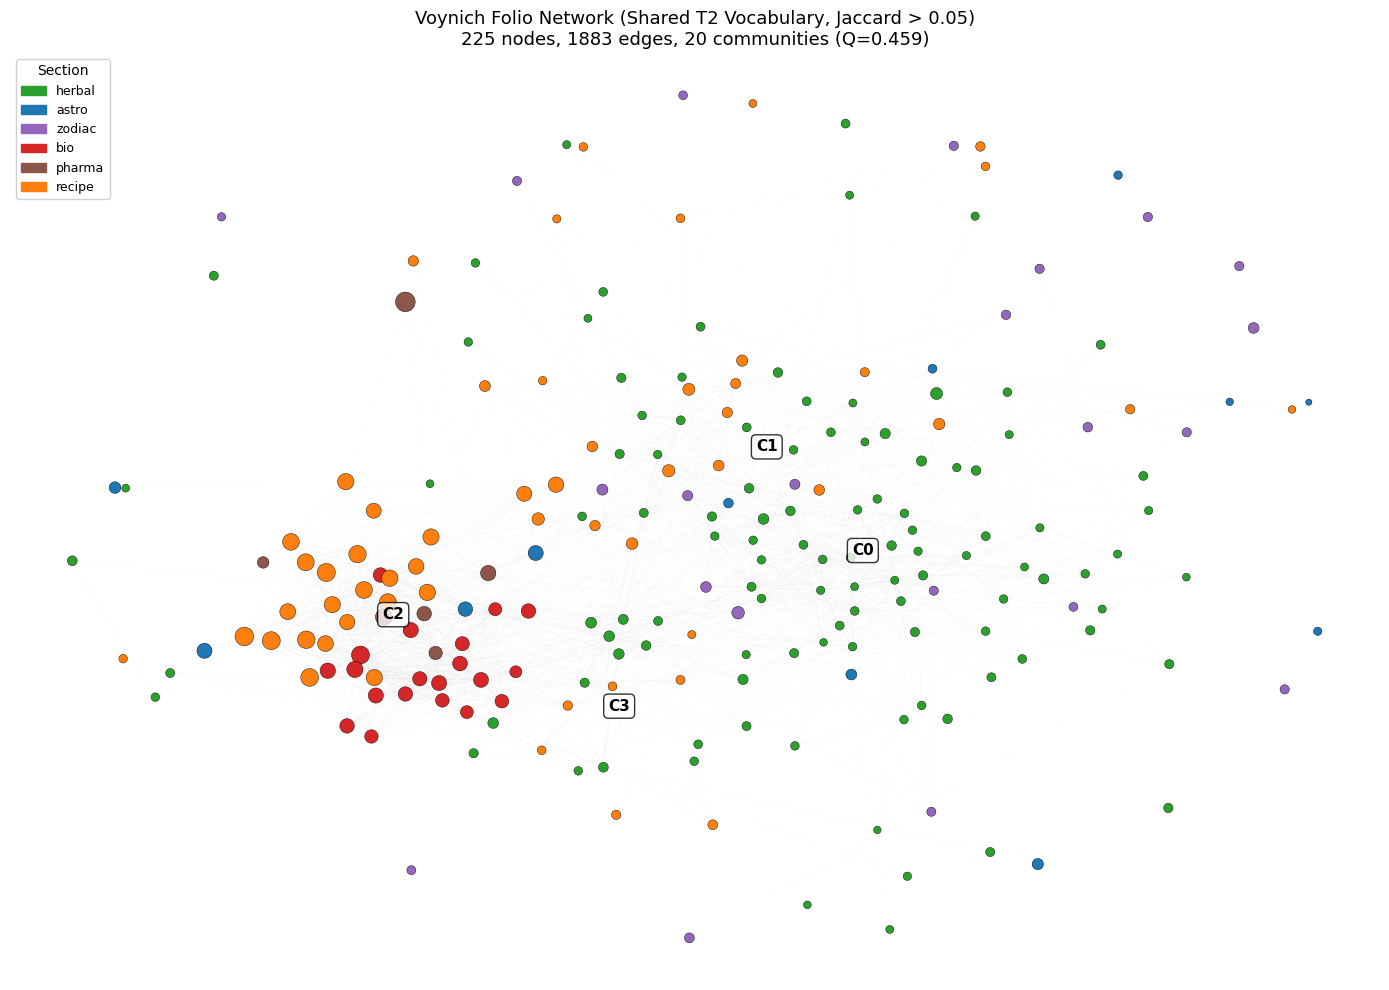

Saved to images/vocabulary_network.png


In [8]:
# ── Cell 8: Network visualisation ───────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

# Spring layout
pos = nx.spring_layout(G, weight='weight', seed=42, k=0.3, iterations=80)

# Node colors by section
node_colors = [SECTION_COLORS.get(folio_section.get(n, 'unknown'), '#7f7f7f')
               for n in G.nodes()]

# Node sizes by word count (scaled)
wc_vals = [folio_word_count.get(n, 10) for n in G.nodes()]
wc_arr = np.array(wc_vals, dtype=float)
node_sizes = 20 + 180 * (wc_arr - wc_arr.min()) / max(wc_arr.max() - wc_arr.min(), 1)

# Edge widths and alpha by Jaccard weight
edges = G.edges(data=True)
edge_weights = [d['weight'] for _, _, d in edges]
if edge_weights:
    ew_arr = np.array(edge_weights)
    edge_alphas = 0.05 + 0.6 * (ew_arr - ew_arr.min()) / max(ew_arr.max() - ew_arr.min(), 1)
    edge_widths = 0.2 + 1.5 * (ew_arr - ew_arr.min()) / max(ew_arr.max() - ew_arr.min(), 1)
else:
    edge_alphas = []
    edge_widths = []

# Draw edges with varying alpha
edge_list = list(G.edges())
for idx, (u, v) in enumerate(edge_list):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    ax.plot([x0, x1], [y0, y1], color='gray',
            alpha=float(edge_alphas[idx]), linewidth=float(edge_widths[idx]))

# Draw nodes
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                       node_size=node_sizes, edgecolors='black', linewidths=0.3)

# Annotate largest communities (label centroids)
for cid, members in enumerate(communities[:5]):
    if len(members) < 3:
        continue
    xs = [pos[n][0] for n in members if n in pos]
    ys = [pos[n][1] for n in members if n in pos]
    if xs:
        cx, cy = np.mean(xs), np.mean(ys)
        ax.annotate(f'C{cid}', (cx, cy), fontsize=11, fontweight='bold',
                    ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                              alpha=0.8, edgecolor='black'))

# Legend
legend_patches = [mpatches.Patch(color=SECTION_COLORS[s], label=s)
                  for s in SECTIONS if s in set(folio_section.values())]
ax.legend(handles=legend_patches, loc='upper left', fontsize=9,
          title='Section', framealpha=0.9)

ax.set_title(f'Voynich Folio Network (Shared T2 Vocabulary, Jaccard > {JACCARD_THRESHOLD})\n'
             f'{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, '
             f'{n_communities} communities (Q={mod_score:.3f})',
             fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.savefig('images/vocabulary_network.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to images/vocabulary_network.png')

In [9]:
# ── Cell 9: Hub analysis ────────────────────────────────────────────
# Find highest-degree nodes (hubs): folios sharing T2 vocabulary with many others.

degree_data = sorted(G.degree(), key=lambda x: x[1], reverse=True)

print(f'TOP 15 HUB FOLIOS (highest degree)')
print(f'={"=" * 70}')
print(f'{"Folio":<12} {"Section":<10} {"Degree":<8} {"Community":<10} {"Words":<8} {"First T2 word"}')
print(f'{"-" * 70}')

for fol, deg in degree_data[:15]:
    sec = folio_section.get(fol, '?')
    comm = node_community.get(fol, '?')
    wc = folio_word_count.get(fol, 0)
    # First T2 word in this folio
    t2_in_folio = df_t2[df_t2['folio'] == fol]
    first_t2 = t2_in_folio.iloc[0]['word_str'] if len(t2_in_folio) > 0 else '-'
    print(f'{fol:<12} {sec:<10} {deg:<8} C{comm:<9} {wc:<8} {first_t2}')

# Also show isolates (degree 0)
isolates = [n for n, d in G.degree() if d == 0]
print(f'\nIsolated folios (degree 0): {len(isolates)}')
if isolates:
    for fol in isolates[:10]:
        sec = folio_section.get(fol, '?')
        wc = folio_word_count.get(fol, 0)
        print(f'  {fol} ({sec}, {wc} words)')
    if len(isolates) > 10:
        print(f'  ... and {len(isolates) - 10} more')

TOP 15 HUB FOLIOS (highest degree)
Folio        Section    Degree   Community  Words    First T2 word
----------------------------------------------------------------------
f86v5        pharma     58       C2         384      P1.L1.B1.A3.B2
f82v         bio        50       C2         314      A1.Q2.J1.K1.B1.A2
f45r         herbal     46       C0         88       P1.A2.Q1.A2.B1.A3.B2
f83v         bio        46       C2         259      P1.A1.B2.B1.A3.Q1.A2
f55r         herbal     45       C3         123      P1.A1.B1.A3.G1
f46v         herbal     44       C3         108      P1.A1.Ba.A2.B2.L1.J1.Ba
f79r         bio        44       C2         377      Lb.J1.B1.A2.P1.K1.A1.C1
f103v        recipe     44       C2         440      P1.A1.B2.B1.A3.C1
f76v         bio        40       C2         389      A1.Q1.Aa.C1
f75r         bio        39       C2         375      Q1.K1.J1.B1.A2.Q1.A3.C1.A2.A1.Q1.K2.A2
f76r         bio        39       C2         552      P1.A1.Q2.K1.A1.Q1.A1.C1
f80r         

## Conclusions

This notebook constructed a co-occurrence network of Voynich manuscript folios based on shared Tier-2 (content) vocabulary and tested whether the resulting communities align with known manuscript sections and onset families.

**Key findings:**

1. **Network structure.** The Jaccard-based folio network reveals the degree of vocabulary overlap between folios. The modularity score and number of connected components characterise how compartmentalised the manuscript's content vocabulary is.

2. **Community-section alignment.** The chi-squared test on the community-section cross-tabulation reveals whether Louvain communities recover the traditional codicological sections (herbal, astro, zodiac, bio, pharma, recipe). A significant result would confirm that content vocabulary is section-specific, consistent with the catalogue-code hypothesis.

3. **Community-onset family alignment.** Testing communities against onset families probes whether vocabulary communities also align with the structural onset categories identified in the code-anatomy analysis.

4. **Hub folios.** High-degree hubs are folios whose T2 vocabulary is shared with many others. These may represent general-purpose entries, cross-referencing points, or thematically central folios within their sections.

In [10]:
# ── Cell 11: Export results ─────────────────────────────────────────
results = {
    'network': {
        'n_nodes': G.number_of_nodes(),
        'n_edges': G.number_of_edges(),
        'mean_degree': float(np.mean(degrees)),
        'connected_components': nx.number_connected_components(G),
        'jaccard_threshold': JACCARD_THRESHOLD,
        'jaccard_mean': float(jaccard_values.mean()),
        'jaccard_max': float(jaccard_values.max()),
    },
    'communities': {
        'method': method_name,
        'n_communities': n_communities,
        'modularity': float(mod_score),
        'sizes': [len(c) for c in communities],
    },
    'chi2_community_section': {
        'chi2': float(chi2),
        'p_value': float(p_val),
        'dof': int(dof),
        'significant': bool(p_val < 0.05),
    },
    'chi2_community_onset_family': {
        'chi2': float(chi2_of),
        'p_value': float(p_of),
        'dof': int(dof_of),
        'significant': bool(p_of < 0.05),
    },
    'hubs_top10': [
        {'folio': fol, 'section': folio_section.get(fol, '?'),
         'degree': deg, 'community': node_community.get(fol, -1)}
        for fol, deg in degree_data[:10]
    ],
    'isolates': len(isolates),
    'folio_communities': {fol: node_community.get(fol, -1) for fol in folios_list},
    't2_matrix_shape': list(mat.shape),
    't2_sparsity': float(1 - (mat > 0).sum() / mat.size),
}

out_path = 'resultados/vocabulary_network_resultados.json'
import os
os.makedirs('resultados', exist_ok=True)
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)
print(f'Results saved to {out_path}')
print(json.dumps(results, indent=2))

Results saved to resultados/vocabulary_network_resultados.json
{
  "network": {
    "n_nodes": 225,
    "n_edges": 1883,
    "mean_degree": 16.73777777777778,
    "connected_components": 17,
    "jaccard_threshold": 0.05,
    "jaccard_mean": 0.023581164553288736,
    "jaccard_max": 0.1282051282051282
  },
  "communities": {
    "method": "Louvain",
    "n_communities": 20,
    "modularity": 0.45882551336929,
    "sizes": [
      72,
      60,
      52,
      25,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1,
      1
    ]
  },
  "chi2_community_section": {
    "chi2": 345.0691433566434,
    "p_value": 4.401569128190328e-30,
    "dof": 95,
    "significant": true
  },
  "chi2_community_onset_family": {
    "chi2": 239.38526748418667,
    "p_value": 1.9178838771433457e-14,
    "dof": 95,
    "significant": true
  },
  "hubs_top10": [
    {
      "folio": "f86v5",
      "section": "pharma",
      "degr